# 07 · Binary classification

Same training loop as regression — three things change: the **output layer**, the **loss**, and the **way you judge the result** (a loss of 0.45 tells a human nothing; accuracy, precision and recall do).

Dataset: the Titanic passenger list used in the lecturer's week 6–8 notebooks. Label: `Survived` (0/1).

---
## Theory in 60 seconds

- Output layer: **one neuron**. Its raw output `z` is called the **logit**; `p = σ(z) = 1/(1+e^{−z})` is the predicted probability of class 1.
- Loss: **binary cross-entropy** `−[y·ln p + (1−y)·ln(1−p)]`, averaged over the batch. It is the negative log of the probability the model assigned to the *correct* answer.
- Two equivalent ways to wire it in PyTorch — **never mix them**:

| | last layer of the model | loss | model output is |
|---|---|---|---|
| lecturer's notebooks | `nn.Linear(…, 1)` + `nn.Sigmoid()` | `nn.BCELoss()` | a probability |
| lab solutions | `nn.Linear(…, 1)` | `nn.BCEWithLogitsLoss()` | a logit |

- Labels for both: `float32`, same shape as the output, `(batch, 1)`.
- Decision: class 1 if `p > 0.5` ⇔ `z > 0`.
- **Accuracy** = correct / all. With imbalanced classes it flatters a useless model, so also look at **precision** = TP/(TP+FP) ("when I say 1, how often am I right?") and **recall** = TP/(TP+FN) ("of the real 1s, how many did I find?"), and **F1** = their harmonic mean.

In [1]:
import sys; sys.path.insert(0, "..")
import csv
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
from dnd_utils import check, DATA, load_titanic_raw, load_titanic

with open(DATA / "titanic.csv") as f:
    for _ in range(4): print(f.readline().rstrip())

PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,0,3,"Braund, Mr. Owen Harris",male,22,1,0,A/5 21171,7.25,,S
2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38,1,0,PC 17599,71.2833,C85,C
3,1,3,"Heikkinen, Miss. Laina",female,26,0,0,STON/O2. 3101282,7.925,,S


---
## Exercise 7.1 · Parsing a CSV with quoted fields

The `Name` field contains commas inside quotes, so `line.split(",")` breaks the columns. Python's built-in `csv` module handles this.

Build, with `csv.reader`:

- `inputs`: `(891, 7)` `float32` with the columns **Pclass, Sex, Age, SibSp, Parch, Fare, Embarked** — `Sex`: female → 0, male → 1; `Embarked`: C → 0, Q → 1, S → 2; empty fields → `np.nan`
- `labels`: `(891,)` `int32`, the `Survived` column

<details><summary>Hint</summary>

```python
with open(path, newline="") as f:
    reader = csv.reader(f)
    header = next(reader)          # first row
    for row in reader:             # each row is a list of strings, quotes already handled
        ...
```
Find the column positions with `header.index("Age")` instead of counting by hand.
</details>

In [2]:
sex_code = {"female": 0.0, "male": 1.0}
emb_code = {"C": 0.0, "Q": 1.0, "S": 2.0}

def to_float(text):
    return float("nan") if text == "" else float(text)

in_rows, lab = [], []
with open(DATA / "titanic.csv", newline="") as f:
    reader = csv.reader(f)
    header = next(reader)
    col = {name: i for i, name in enumerate(header)}             # column name -> position
    for row in reader:
        lab.append(int(row[col["Survived"]]))
        emb = row[col["Embarked"]]
        in_rows.append([to_float(row[col["Pclass"]]), sex_code[row[col["Sex"]]], to_float(row[col["Age"]]),
                        to_float(row[col["SibSp"]]), to_float(row[col["Parch"]]), to_float(row[col["Fare"]]),
                        float("nan") if emb == "" else emb_code[emb]])
inputs = np.array(in_rows, dtype=np.float32)
labels = np.array(lab, dtype=np.int32)
print(inputs.shape, labels.shape, np.isnan(inputs).sum(axis=0))

(891, 7) (891,) [  0   0 177   0   0   0   2]


In [3]:
_ri, _rl = load_titanic_raw()
check("inputs: shape and dtype", lambda: inputs.shape == (891, 7) and inputs.dtype == np.float32)
check("inputs: values", lambda: np.allclose(inputs, _ri, equal_nan=True))
check("labels", lambda: labels.shape == (891,) and labels.dtype == np.int32 and (labels == _rl).all())

✅ inputs: shape and dtype
✅ inputs: values
✅ labels


True

The rest of the preprocessing is what you built in notebook 04 (flag + median for `Age`, one-hot for `Embarked`, shuffle, 60/20/20 split, standardisation with training statistics). To keep this notebook focused it is loaded ready-made:

In [4]:
d = load_titanic()
X_train, y_train = d["X_train"], d["y_train"]        # (534, 10) float32, (534,) float32 in {0, 1}
X_val, y_val = d["X_val"], d["y_val"]
X_test, y_test = d["X_test"], d["y_test"]
print(X_train.shape, y_train.shape, y_train.dtype, "| columns: Pclass Age SibSp Parch Fare | Sex | Emb C Q S | Age-missing")

(534, 10) (534,) float32 | columns: Pclass Age SibSp Parch Fare | Sex | Emb C Q S | Age-missing


---
## Exercise 7.2 · Know your classes before you train

Compute the fraction of survivors in the training set, and `baseline_acc`: the **test** accuracy of the laziest classifier — always predict the class that is the majority in the **training** set.

In [5]:
pos_rate_train = float(y_train.mean())                      # mean of 0/1 labels = fraction of ones
majority = 1.0 if pos_rate_train > 0.5 else 0.0             # here: 0 ("did not survive")
baseline_acc = float((y_test == majority).mean())
print(pos_rate_train, baseline_acc)

0.36329588294029236 0.6145251396648045


In [6]:
check("pos_rate_train ≈ 0.36", lambda: abs(pos_rate_train - y_train.mean()) < 1e-6)
check("baseline_acc", lambda: abs(baseline_acc - (y_test == 0).mean()) < 1e-6)

✅ pos_rate_train ≈ 0.36
✅ baseline_acc


True

Any model you train must be judged against this number, not against 50 %.

---
## Exercise 7.3 · Binary cross-entropy by hand

**a)** Implement `my_bce(p, y)`: mean BCE from **probabilities** (tensors of equal shape).

**b)** Implement `my_bce_with_logits(z, y)`: mean BCE from **logits**, in the numerically stable form

$$\ell(z, y) = \max(z, 0) - z\,y + \ln\!\big(1 + e^{-|z|}\big)$$

(Optional, on paper: show that this equals `−[y ln σ(z) + (1−y) ln(1−σ(z))]`.)

In [7]:
def my_bce(p, y):
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p)).mean()

def my_bce_with_logits(z, y):
    return (torch.clamp(z, min=0) - z * y + torch.log(1 + torch.exp(-torch.abs(z)))).mean()

In [8]:
torch.manual_seed(0)
_z = torch.randn(50, 1) * 3
_y = (torch.rand(50, 1) < 0.4).float()
check("my_bce == nn.BCELoss", lambda: torch.allclose(my_bce(torch.sigmoid(_z), _y), nn.BCELoss()(torch.sigmoid(_z), _y), atol=1e-5))
check("my_bce_with_logits == nn.BCEWithLogitsLoss", lambda: torch.allclose(my_bce_with_logits(_z, _y), nn.BCEWithLogitsLoss()(_z, _y), atol=1e-6))
check("both routes give the same number", lambda: torch.allclose(my_bce(torch.sigmoid(_z), _y), my_bce_with_logits(_z, _y), atol=1e-5))

✅ my_bce == nn.BCELoss
✅ my_bce_with_logits == nn.BCEWithLogitsLoss
✅ both routes give the same number


True

**c)** Fill in the table by reasoning (then verify with your function): the loss of a **single** sample with true label `y = 1` when the model predicts the given probability.

In [9]:
loss_when_p_is = {0.99: 0.01, 0.5: 0.69, 0.01: 4.61}       # -ln(p): confident & right ~0, coin flip ln 2, confident & wrong large

In [10]:
for p_, l_ in loss_when_p_is.items():
    check(f"p = {p_}: loss = {-np.log(p_):.2f}", lambda: abs(l_ - (-np.log(p_))) < 0.006)

✅ p = 0.99: loss = 0.01
✅ p = 0.5: loss = 0.69
✅ p = 0.01: loss = 4.61


The loss is **unbounded** for confident wrong answers: one sample predicted with `p = 0.01` costs as much as 460 samples predicted with `p = 0.99`. Cross-entropy punishes over-confidence — that is its job.

**d)** Why does the logits version exist at all? Run the cell and explain the difference in the last column.

In [11]:
for z_val in (-5.0, -20.0, -40.0):
    z1 = torch.tensor([[z_val]], requires_grad=True)
    nn.BCELoss()(torch.sigmoid(z1), torch.ones(1, 1)).backward()
    z2 = torch.tensor([[z_val]], requires_grad=True)
    nn.BCEWithLogitsLoss()(z2, torch.ones(1, 1)).backward()
    print(f"logit {z_val:6.1f} (true label 1)   gradient via Sigmoid+BCELoss: {z1.grad.item():10.6f}   via BCEWithLogitsLoss: {z2.grad.item():10.6f}")

logit   -5.0 (true label 1)   gradient via Sigmoid+BCELoss:  -0.993307   via BCEWithLogitsLoss:  -0.993307
logit  -20.0 (true label 1)   gradient via Sigmoid+BCELoss:  -1.000000   via BCEWithLogitsLoss:  -1.000000
logit  -40.0 (true label 1)   gradient via Sigmoid+BCELoss:  -0.000004   via BCEWithLogitsLoss:  -1.000000


**Answer.** The correct gradient is `p − y ≈ −1`: a badly wrong prediction should get a strong push. With `Sigmoid` + `BCELoss` the chain rule multiplies two extreme numbers — the loss's derivative `−1/p` (huge, because `p = σ(−40) ≈ 4·10⁻¹⁸`) and the sigmoid's derivative `p(1−p)` (tiny). To avoid dividing by zero, `BCELoss` limits how large the first factor may become (and clamps `ln p` at −100), so for extreme logits the product is no longer −1 but collapses towards 0: the sample that is *most* wrong stops teaching the network. `BCEWithLogitsLoss` never forms `σ(z)` explicitly (it uses the stable formula from b), so its gradient is exactly `σ(z) − y`. In well-scaled problems both variants work; the logits version is simply the safe default.

---
## Exercise 7.4 · Two models, two accuracy functions

Architecture `10 → 30 → 20 → 1` with ReLU.

- `BinMLPProb`: ends with a sigmoid (outputs probabilities) — to be used with `nn.BCELoss`.
- `BinMLPLogit`: no final activation (outputs logits) — to be used with `nn.BCEWithLogitsLoss`.
- `acc_from_probs(p, y)` and `acc_from_logits(z, y)`: fraction of correct predictions as a tensor scalar or float; inputs have shape `(batch, 1)`.

In [12]:
class BinMLPProb(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_inputs, 30), nn.ReLU(), nn.Linear(30, 20), nn.ReLU(),
                                    nn.Linear(20, 1), nn.Sigmoid())
    def forward(self, x):
        return self.layers(x)

class BinMLPLogit(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_inputs, 30), nn.ReLU(), nn.Linear(30, 20), nn.ReLU(),
                                    nn.Linear(20, 1))
    def forward(self, x):
        return self.layers(x)

def acc_from_probs(p, y):
    assert p.shape == y.shape                      # guards against the (n,1) vs (n,) broadcast
    return ((p > 0.5).float() == y).float().mean().item()

def acc_from_logits(z, y):
    assert z.shape == y.shape
    return ((z > 0).float() == y).float().mean().item()

In [13]:
_x = torch.randn(64, 10)
check("BinMLPProb outputs probabilities, shape (64, 1)", lambda: (lambda o: o.shape == (64, 1) and 0 < o.min() and o.max() < 1)(BinMLPProb(10)(_x)))
check("BinMLPLogit outputs unbounded logits, shape (64, 1)", lambda: (lambda o: o.shape == (64, 1) and o.min() < 0)((torch.manual_seed(1), BinMLPLogit(10))[1](_x * 5)))
_p = torch.tensor([[0.9], [0.2], [0.6], [0.4]]); _yy = torch.tensor([[1.0], [0.0], [0.0], [0.0]])
check("acc_from_probs", lambda: abs(float(acc_from_probs(_p, _yy)) - 0.75) < 1e-6)
check("acc_from_logits", lambda: abs(float(acc_from_logits(torch.logit(_p), _yy)) - 0.75) < 1e-6)

✅ BinMLPProb outputs probabilities, shape (64, 1)
✅ BinMLPLogit outputs unbounded logits, shape (64, 1)
✅ acc_from_probs
✅ acc_from_logits


True

---
## Exercise 7.5 · Train it

1. Write the `Dataset` (labels `float32`, batches `(batch, 1)`) and three loaders (batch size 32).
2. Train a fresh `BinMLPLogit` for 60 epochs with `BCEWithLogitsLoss` and `Adam(lr=0.001)`.
3. Per epoch record `train_losses`, `val_losses`, `train_accs`, `val_accs` (mean over batches is fine).
4. **Before** the first update, store the validation loss of the untrained model in `initial_val_loss`.

In [14]:
class BinaryDataset(Dataset):
    def __init__(self, x, y):
        self.xs = torch.tensor(x, dtype=torch.float32)
        self.ys = torch.tensor(y, dtype=torch.float32)          # "true probabilities" 0.0 / 1.0
    def __len__(self):
        return self.xs.shape[0]
    def __getitem__(self, idx):
        return self.xs[idx], self.ys[idx, None]

loader_train = DataLoader(BinaryDataset(X_train, y_train), batch_size=32, shuffle=True)
loader_val = DataLoader(BinaryDataset(X_val, y_val), batch_size=32, shuffle=True)
loader_test = DataLoader(BinaryDataset(X_test, y_test), batch_size=32, shuffle=False)

def run_epoch(model, loader, loss_fn, optimizer=None):
    """One pass. Trains if an optimizer is given, otherwise only evaluates. Returns (mean loss, mean accuracy)."""
    training = optimizer is not None
    model.train() if training else model.eval()
    losses, accs = [], []
    with torch.set_grad_enabled(training):           # same as no_grad() when evaluating
        for xb, yb in loader:
            z = model(xb)
            loss = loss_fn(z, yb)
            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
            losses.append(loss.item())
            accs.append(acc_from_logits(z, yb))
    return float(np.mean(losses)), float(np.mean(accs))

torch.manual_seed(0)
model = BinMLPLogit(X_train.shape[1])
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

initial_val_loss, _ = run_epoch(model, loader_val, loss_fn)
train_losses, val_losses, train_accs, val_accs = [], [], [], []
for epoch in range(60):
    tl, ta = run_epoch(model, loader_train, loss_fn, optimizer)
    vl, va = run_epoch(model, loader_val, loss_fn)
    train_losses.append(tl); val_losses.append(vl); train_accs.append(ta); val_accs.append(va)
    if epoch % 10 == 0 or epoch == 59:
        print(f"epoch {epoch:2d}  train loss {tl:.3f} acc {ta:.3f}   val loss {vl:.3f} acc {va:.3f}")
print("initial validation loss:", initial_val_loss)

epoch  0  train loss 0.694 acc 0.471   val loss 0.689 acc 0.564
epoch 10  train loss 0.465 acc 0.774   val loss 0.501 acc 0.736


epoch 20  train loss 0.407 acc 0.820   val loss 0.466 acc 0.771
epoch 30  train loss 0.396 acc 0.831   val loss 0.471 acc 0.771


epoch 40  train loss 0.381 acc 0.836   val loss 0.460 acc 0.789
epoch 50  train loss 0.371 acc 0.845   val loss 0.446 acc 0.789


epoch 59  train loss 0.359 acc 0.838   val loss 0.466 acc 0.781
initial validation loss: 0.704245924949646


In [15]:
check("initial loss is close to ln 2 = 0.693", lambda: abs(initial_val_loss - np.log(2)) < 0.08)
check("60 epochs recorded", lambda: len(train_losses) == len(val_losses) == len(train_accs) == len(val_accs) == 60)
check("training loss went down clearly", lambda: train_losses[-1] < 0.5)
check("validation accuracy clearly above the baseline", lambda: val_accs[-1] > 0.75)

✅ initial loss is close to ln 2 = 0.693
✅ 60 epochs recorded
✅ training loss went down clearly
✅ validation accuracy clearly above the baseline


True

Plot two panels side by side: losses (train/val) and accuracies (train/val), each with a legend.

<details><summary>Hint</summary>

`fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))`, then `ax1.plot(...)`, `ax1.set_xlabel(...)`, `ax1.legend()`.
</details>

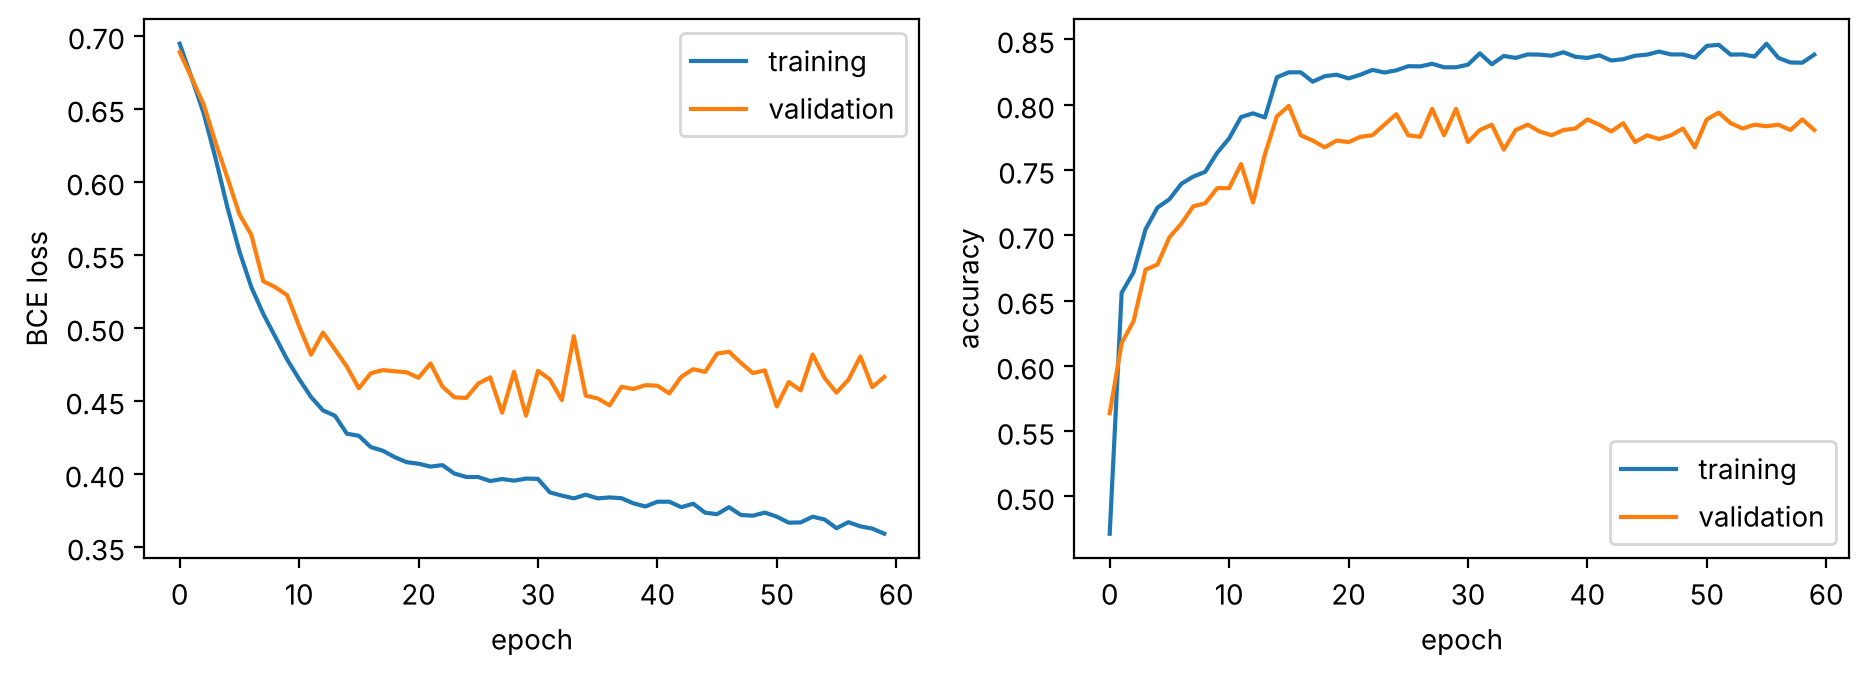

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.5))
ax1.plot(train_losses, label="training"); ax1.plot(val_losses, label="validation")
ax1.set_xlabel("epoch"); ax1.set_ylabel("BCE loss"); ax1.legend()
ax2.plot(train_accs, label="training"); ax2.plot(val_accs, label="validation")
ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend()
plt.show()

The loss curve is smooth, the accuracy curve is jagged, and sometimes the loss improves while the accuracy does not move. Why — and why do we train on the loss rather than directly on accuracy?

**Answer.** Accuracy only changes when a prediction **crosses the threshold**; moving a probability from 0.55 to 0.95 improves the loss but not the accuracy, and with ~180 validation samples one flipped prediction moves accuracy by 0.6 points — hence the steps. Accuracy is a piecewise-constant function of the weights: its gradient is zero almost everywhere, so gradient descent cannot use it. Cross-entropy is a smooth surrogate that rewards moving probabilities in the right direction. We *optimise* the loss and *report* the metric.

---
## Exercise 7.6 · Evaluate on the test set

Compute on the full test set (concatenate the batches):

- `test_logits`, `test_true`: tensors `(179, 1)`
- `test_loss`, `test_acc`
- the four confusion counts `TP, FP, FN, TN` (Python ints; "positive" = survived = 1)
- `precision`, `recall`, `f1`

In [17]:
model.eval()
zs, ys = [], []
with torch.no_grad():
    for xb, yb in loader_test:
        zs.append(model(xb)); ys.append(yb)
test_logits, test_true = torch.cat(zs), torch.cat(ys)

test_loss = loss_fn(test_logits, test_true).item()
test_acc = acc_from_logits(test_logits, test_true)

pred = (test_logits > 0).float()
TP = int(((pred == 1) & (test_true == 1)).sum())       # said 1, was 1
FP = int(((pred == 1) & (test_true == 0)).sum())       # said 1, was 0  (false alarm)
FN = int(((pred == 0) & (test_true == 1)).sum())       # said 0, was 1  (missed)
TN = int(((pred == 0) & (test_true == 0)).sum())
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
print(f"test loss {test_loss:.3f}   accuracy {test_acc:.3f}   (baseline {baseline_acc:.3f})")
print(f"TP {TP}  FP {FP}  FN {FN}  TN {TN}   precision {precision:.3f}  recall {recall:.3f}  F1 {f1:.3f}")

test loss 0.399   accuracy 0.832   (baseline 0.615)
TP 49  FP 10  FN 20  TN 100   precision 0.831  recall 0.710  F1 0.766


In [18]:
check("shapes (179, 1)", lambda: test_logits.shape == test_true.shape == (179, 1))
check("the four counts add up to 179", lambda: TP + FP + FN + TN == 179)
check("accuracy == (TP + TN) / n", lambda: abs(test_acc - (TP + TN) / 179) < 1e-6)
check("TP + FN == number of survivors in the test set", lambda: TP + FN == int(y_test.sum()))
check("precision, recall, f1 consistent", lambda: abs(precision - TP / (TP + FP)) < 1e-9 and abs(recall - TP / (TP + FN)) < 1e-9 and abs(f1 - 2 * TP / (2 * TP + FP + FN)) < 1e-9)
check("clearly better than the majority baseline", lambda: test_acc > baseline_acc + 0.1)

✅ shapes (179, 1)
✅ the four counts add up to 179
✅ accuracy == (TP + TN) / n
✅ TP + FN == number of survivors in the test set
✅ precision, recall, f1 consistent
✅ clearly better than the majority baseline


True

Your model probably has **higher precision than recall**: it misses a fair number of survivors. One reason is the class imbalance (62 % / 38 %) — when unsure, guessing "did not survive" is the safer bet for the loss. The next exercises are the two standard remedies from the lecture.

---
## Exercise 7.7 · Remedy 1: a weighted loss

Idea: multiply the loss of every **positive** sample by `w_pos > 1`, so that mistakes on the minority class cost more.

**a)** Implement `weighted_bce_with_logits(z, y, w_pos)` using `nn.BCEWithLogitsLoss(reduction="none")`: get the per-sample losses, multiply by a weight tensor that is `w_pos` where `y == 1` and `1` elsewhere, then take the mean.

In [19]:
def weighted_bce_with_logits(z, y, w_pos):
    per_sample = nn.BCEWithLogitsLoss(reduction="none")(z, y)        # (batch, 1): one loss per sample, not averaged
    weights = torch.where(y == 1, w_pos, 1.0)                        # (batch, 1): SAME shape as per_sample
    return (per_sample * weights).mean()

In [20]:
check("w_pos = 1 gives the ordinary loss", lambda: torch.allclose(weighted_bce_with_logits(_z, _y, 1.0), nn.BCEWithLogitsLoss()(_z, _y)))
check("equals PyTorch's built-in pos_weight", lambda: torch.allclose(weighted_bce_with_logits(_z, _y, 3.0), nn.BCEWithLogitsLoss(pos_weight=torch.tensor(3.0))(_z, _y), atol=1e-6))
check("returns a scalar", lambda: weighted_bce_with_logits(_z, _y, 3.0).ndim == 0)

✅ w_pos = 1 gives the ordinary loss
✅ equals PyTorch's built-in pos_weight
✅ returns a scalar


True

**b)** The shape trap of this technique. `per_sample` has shape `(batch, 1)`. Suppose your weights came from a 1-D label array and have shape `(batch,)`. Predict the shape of `per_sample * weights` and whether the resulting "loss" is still correct.

In [21]:
trap_shape_for_batch_50 = (50, 50)   # (50,1) * (50,) broadcasts to a full matrix: every loss times EVERY weight
trap_is_correct = False              # the mean then equals mean(loss) * mean(weight): the weighting is silently lost

In [22]:
_per = nn.BCEWithLogitsLoss(reduction="none")(_z, _y); _w1d = torch.where(_y[:, 0] == 1, 3.0, 1.0)
check("shape", lambda: tuple(trap_shape_for_batch_50) == tuple((_per * _w1d).shape))
check("correctness", lambda: trap_is_correct is False and not torch.allclose((_per * _w1d).mean(), weighted_bce_with_logits(_z, _y, 3.0)))
print("buggy value:", (_per * _w1d).mean().item(), "= mean(loss) * mean(weight) =", (_per.mean() * _w1d.mean()).item(), "| correct:", weighted_bce_with_logits(_z, _y, 3.0).item())

✅ shape
✅ correctness
buggy value: 2.189758539199829 = mean(loss) * mean(weight) = 2.189758777618408 | correct: 2.1288809776306152


**c)** Train a fresh `BinMLPLogit` exactly as in 7.5, but with the weighted loss and `w_pos = (number of negatives) / (number of positives)` in the training set. Then compute `recall_w`, `precision_w`, `acc_w` on the test set.

<details><summary>Hint</summary>

Your training code takes a `loss_fn(z, y)`. Either pass `nn.BCEWithLogitsLoss(pos_weight=torch.tensor(w_pos))`, or wrap your own function: `lambda z, y: weighted_bce_with_logits(z, y, w_pos)`.
</details>

In [23]:
w_pos = float((y_train == 0).sum() / (y_train == 1).sum())
weighted_loss = lambda z, y: weighted_bce_with_logits(z, y, w_pos)

torch.manual_seed(0)
model_w = BinMLPLogit(X_train.shape[1])
opt_w = torch.optim.Adam(model_w.parameters(), lr=0.001)
for epoch in range(60):
    run_epoch(model_w, loader_train, weighted_loss, opt_w)

model_w.eval()
with torch.no_grad():
    z_w = model_w(torch.tensor(X_test))
y_te = torch.tensor(y_test)[:, None]
pred_w = (z_w > 0).float()
tp = ((pred_w == 1) & (y_te == 1)).sum().item(); fp = ((pred_w == 1) & (y_te == 0)).sum().item(); fn = ((pred_w == 0) & (y_te == 1)).sum().item()
recall_w, precision_w, acc_w = tp / (tp + fn), tp / (tp + fp), (pred_w == y_te).float().mean().item()
print(f"w_pos = {w_pos:.2f}")
print(f"plain    : accuracy {test_acc:.3f}  precision {precision:.3f}  recall {recall:.3f}")
print(f"weighted : accuracy {acc_w:.3f}  precision {precision_w:.3f}  recall {recall_w:.3f}")

w_pos = 1.75
plain    : accuracy 0.832  precision 0.831  recall 0.710
weighted : accuracy 0.827  precision 0.764  recall 0.797


In [24]:
check("w_pos = n_neg / n_pos", lambda: abs(w_pos - (y_train == 0).sum() / (y_train == 1).sum()) < 1e-6)
check("recall did not get worse (usually it rises)", lambda: recall_w >= recall - 0.02)
check("still a sensible classifier", lambda: acc_w > baseline_acc + 0.08)

✅ w_pos = n_neg / n_pos
✅ recall did not get worse (usually it rises)
✅ still a sensible classifier


True

Weighting typically **raises recall and lowers precision**: the model says "survived" more readily. Whether that is an improvement depends on which mistake is more expensive in the application — it is a decision, not a free lunch.

---
## Exercise 7.8 · Remedy 2: balanced mini-batches

Instead of re-weighting the loss, feed the network batches with **equally many samples of each class**.

Write the generator `balanced_batches(X, y, batch_size, n_batches, rng)`:

- `X`: tensor `(n, d)`; `y`: tensor `(n,)` with values 0.0/1.0; `batch_size` is even
- every batch contains `batch_size // 2` randomly chosen positives and `batch_size // 2` randomly chosen negatives (sampling **with** replacement, so the minority class may repeat)
- yields `(xb, yb)` with `yb` of shape `(batch_size, 1)`

<details><summary>Hint</summary>

Compute the index arrays of each class once: `pos_idx = np.where(y.numpy() == 1)[0]`. In each batch draw `rng.choice(pos_idx, size=batch_size // 2)` and the same for the negatives, concatenate the two index arrays, index `X` and `y`.
</details>

In [25]:
def balanced_batches(X, y, batch_size, n_batches, rng):
    y_np = y.numpy()
    pos_idx = np.where(y_np == 1)[0]
    neg_idx = np.where(y_np == 0)[0]
    half = batch_size // 2
    for _ in range(n_batches):
        idx = np.concatenate([rng.choice(pos_idx, size=half), rng.choice(neg_idx, size=half)])   # replace=True by default
        idx = torch.as_tensor(idx)
        yield X[idx], y[idx, None]

In [26]:
_Xt, _yt = torch.tensor(X_train), torch.tensor(y_train)
_bb = None
try: _bb = list(balanced_batches(_Xt, _yt, 32, 10, np.random.default_rng(0)))
except NotImplementedError: pass
check("10 batches of shapes (32, 10) and (32, 1)", lambda: len(_bb) == 10 and all(x.shape == (32, 10) and y.shape == (32, 1) for x, y in _bb))
check("every batch is exactly half positive", lambda: all(y.sum().item() == 16 for _, y in _bb))
check("inputs and labels stay paired", lambda: all(any(torch.equal(_bb[0][0][i], _Xt[j]) for j in (_yt == _bb[0][1][i, 0]).nonzero()[:, 0]) for i in (0, 20)))
check("batches differ from each other", lambda: not torch.equal(_bb[0][0], _bb[1][0]))

✅ 10 batches of shapes (32, 10) and (32, 1)
✅ every batch is exactly half positive
✅ inputs and labels stay paired
✅ batches differ from each other


True

With such a generator there is no natural "epoch" any more (samples are drawn at random with replacement). How would you decide how many batches make up one epoch? And should the **validation** data also be balanced this way?

**Answer.** A common convention is `n_batches = len(training set) // batch_size`, so that one "epoch" processes about as many samples as before. Validation and test data should **not** be resampled: they are meant to measure performance on the real distribution. Keep them as they are and use metrics that are meaningful under imbalance (precision, recall, F1, the confusion matrix).

---
## Exercise 7.9 · Moving the threshold

The 0.5 threshold is a choice. Write `prf_at(logits, y, threshold)` that returns `(precision, recall)` when class 1 is predicted for `p > threshold`. If the model predicts no positives at all, return precision `0.0`. Use it on the **plain** model's test logits for thresholds 0.3, 0.5 and 0.7.

In [27]:
def prf_at(logits, y, threshold):
    pred = (torch.sigmoid(logits) > threshold).float()
    tp = ((pred == 1) & (y == 1)).sum().item()
    fp = ((pred == 1) & (y == 0)).sum().item()
    fn = ((pred == 0) & (y == 1)).sum().item()
    precision = tp / (tp + fp) if tp + fp > 0 else 0.0        # guard against 0 / 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    return precision, recall

In [28]:
for thr in (0.3, 0.5, 0.7):
    try: print(f"threshold {thr}: precision %.3f  recall %.3f" % prf_at(test_logits, test_true, thr))
    except Exception as e: print(type(e).__name__)
check("threshold 0.5 reproduces 7.6", lambda: np.allclose(prf_at(test_logits, test_true, 0.5), (precision, recall)))
check("lower threshold -> recall does not decrease", lambda: prf_at(test_logits, test_true, 0.3)[1] >= prf_at(test_logits, test_true, 0.5)[1] >= prf_at(test_logits, test_true, 0.7)[1])
check("no positives predicted -> precision 0.0, no crash", lambda: prf_at(test_logits, test_true, 1.0) == (0.0, 0.0))

threshold 0.3: precision 0.722  recall 0.826
threshold 0.5: precision 0.831  recall 0.710
threshold 0.7: precision 0.932  recall 0.594
✅ threshold 0.5 reproduces 7.6
✅ lower threshold -> recall does not decrease
✅ no positives predicted -> precision 0.0, no crash


True

---
## Exercise 7.10 · Bug hunt: the double sigmoid

Someone combined the two recipes: a model that ends in `nn.Sigmoid()` **and** `nn.BCEWithLogitsLoss`. There is no error and no warning.

**a)** The loss function now receives a number between 0 and 1 and treats it as a logit. What is the smallest loss it can ever give for a sample with `y = 1`? For a sample with `y = 0`? (Use the formula `ℓ = ln(1 + e^{−z})` for `y = 1` and `ℓ = ln(1 + e^{z})` for `y = 0`, with `z` restricted to `[0, 1]`.)

In [29]:
min_loss_y1 = float(np.log(1 + np.exp(-1.0)))     # best case z -> 1:  0.313   (cannot get more confident than "logit 1")
min_loss_y0 = float(np.log(1 + np.exp(0.0)))      # best case z -> 0:  0.693 = ln 2   (a "logit" of 0 means p = 0.5!)

In [30]:
check("min loss for y = 1 is 0.313", lambda: abs(min_loss_y1 - 0.3133) < 1e-3)
check("min loss for y = 0 is 0.693", lambda: abs(min_loss_y0 - 0.6931) < 1e-3)

✅ min loss for y = 1 is 0.313
✅ min loss for y = 0 is 0.693


True

**b)** Run the buggy training below. Then explain the two fingerprints: the value at which the loss gets stuck, and the accuracy you get if you (consistently with the loss) threshold `sigmoid(output) > 0.5`.

In [31]:
torch.manual_seed(0)
buggy = BinMLPProb(X_train.shape[1])                       # ends with Sigmoid ...
buggy_loss = nn.BCEWithLogitsLoss()                        # ... and the loss applies a second one
buggy_opt = torch.optim.Adam(buggy.parameters(), lr=0.001)
try:
    for epoch in range(60):
        buggy.train()
        ep = []
        for xb, yb in loader_train:
            loss = buggy_loss(buggy(xb), yb)
            buggy_opt.zero_grad(); loss.backward(); buggy_opt.step()
            ep.append(loss.item())
        if epoch % 20 == 0 or epoch == 59: print(f"epoch {epoch:2d}  training loss {np.mean(ep):.3f}")
    with torch.no_grad():
        out = buggy(torch.tensor(X_test))
    print("accuracy with sigmoid(output) > 0.5:", ((torch.sigmoid(out) > 0.5).float()[:, 0] == torch.tensor(y_test)).float().mean().item())
    print("accuracy with        output  > 0.5:", ((out > 0.5).float()[:, 0] == torch.tensor(y_test)).float().mean().item())
    print("theoretical floor of the loss: %.3f" % (y_train.mean() * 0.3133 + (1 - y_train.mean()) * 0.6931))
except NameError as e:
    print("finish the exercises above first:", e)

epoch  0  training loss 0.792


epoch 20  training loss 0.647


epoch 40  training loss 0.629


epoch 59  training loss 0.628
accuracy with sigmoid(output) > 0.5: 0.3854748606681824
accuracy with        output  > 0.5: 0.8379888534545898
theoretical floor of the loss: 0.555


**Answer.** The loss cannot go below `0.36·0.313 + 0.64·0.693 ≈ 0.55`: a negative sample costs at least `ln 2` because the smallest "logit" the model can emit is 0, which the loss reads as p = 0.5. So the curve flattens a little above that floor (here ≈ 0.63) instead of reaching ~0.4. Thresholding `sigmoid(output) > 0.5` predicts **class 1 for every sample** (the output is always > 0), giving an accuracy equal to the positive rate (~38 %) — worse than the majority baseline. The model has in fact learned something useful (thresholding the output itself at 0.5 gives a normal accuracy), which makes this bug confusing. Fingerprint: *binary loss stuck around 0.55–0.69 and/or all predictions are class 1* → check for a doubled sigmoid.

---
## Blank-page drill

New empty notebook, 25 minutes, nothing to look at. Starting from `d = load_titanic()`:

1. dataset + loaders;
2. a model `10 → 30 → 20 → 1` — this time in the **lecturer's style**: `nn.Sigmoid()` at the end and `nn.BCELoss()`;
3. a training loop recording loss **and accuracy** for training and validation;
4. the two-panel plot;
5. test loss, test accuracy, and precision / recall / F1 computed by hand;
6. one sentence: is the model better than the majority baseline?

The solution notebook contains this variant at the end.

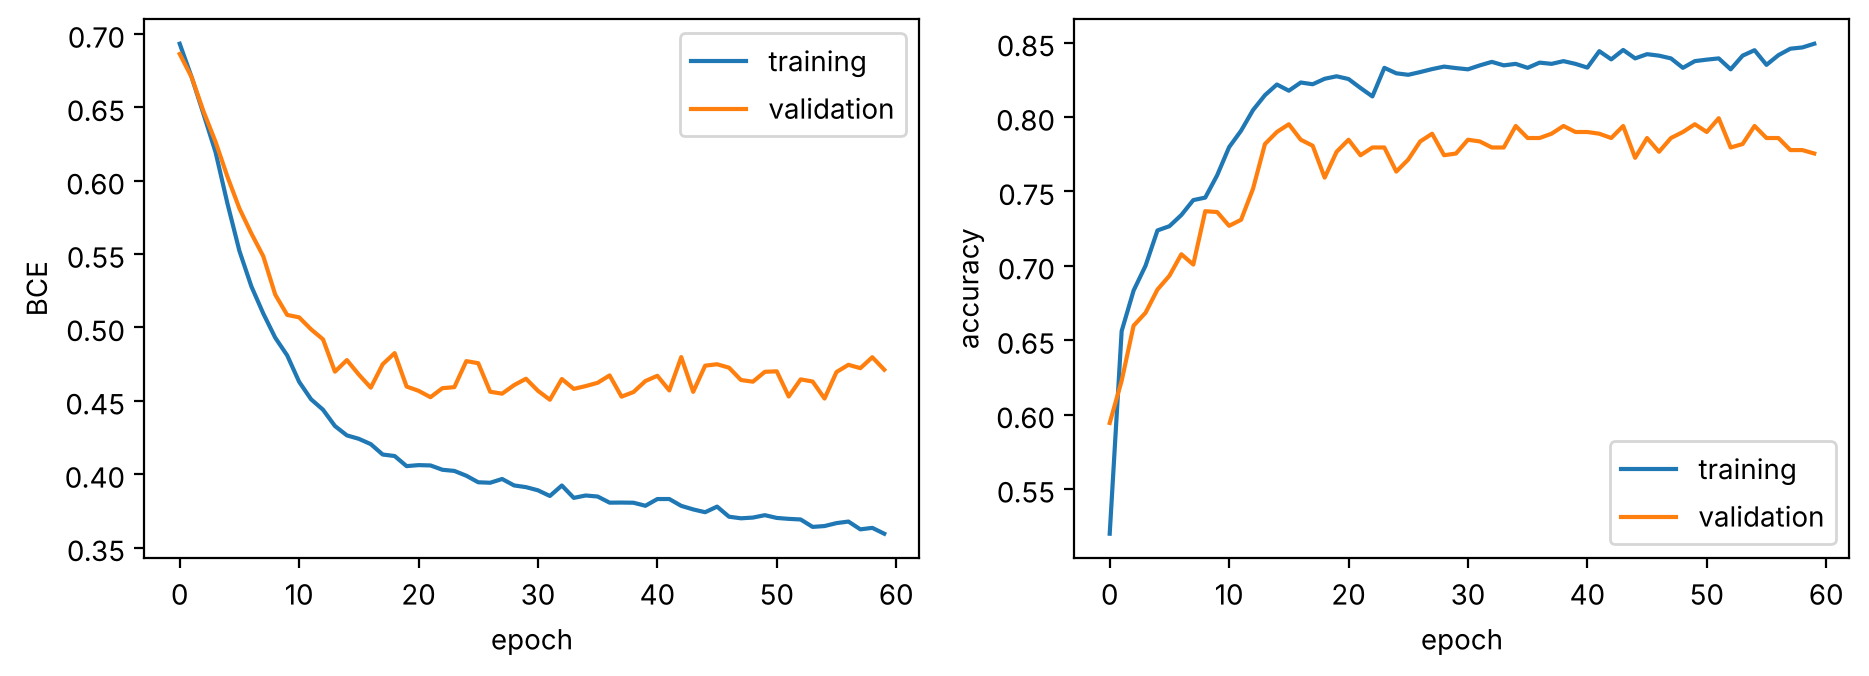

test loss 0.400  acc 0.832  precision 0.831  recall 0.710  F1 0.766  baseline 0.615


In [32]:
# Lecturer's style: Sigmoid in the model + BCELoss; predictions are probabilities.
class ProbNet(nn.Module):
    def __init__(self, n_inputs):
        super().__init__()
        self.layers = nn.Sequential(nn.Linear(n_inputs, 30), nn.ReLU(), nn.Linear(30, 20), nn.ReLU(),
                                    nn.Linear(20, 1), nn.Sigmoid())
    def forward(self, x):
        return self.layers(x)

torch.manual_seed(0)
net = ProbNet(X_train.shape[1])
bce = nn.BCELoss()
opt = torch.optim.Adam(net.parameters(), lr=0.001)
hist = {"tl": [], "vl": [], "ta": [], "va": []}
for epoch in range(60):
    net.train()
    ls, ac = [], []
    for xb, yb in loader_train:
        p = net(xb)
        loss = bce(p, yb)
        opt.zero_grad(); loss.backward(); opt.step()
        ls.append(loss.item()); ac.append((torch.round(p) == yb).float().mean().item())
    hist["tl"].append(np.mean(ls)); hist["ta"].append(np.mean(ac))
    net.eval()
    ls, ac = [], []
    with torch.no_grad():
        for xb, yb in loader_val:
            p = net(xb)
            ls.append(bce(p, yb).item()); ac.append((torch.round(p) == yb).float().mean().item())
    hist["vl"].append(np.mean(ls)); hist["va"].append(np.mean(ac))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(hist["tl"], label="training"); a1.plot(hist["vl"], label="validation"); a1.set_xlabel("epoch"); a1.set_ylabel("BCE"); a1.legend()
a2.plot(hist["ta"], label="training"); a2.plot(hist["va"], label="validation"); a2.set_xlabel("epoch"); a2.set_ylabel("accuracy"); a2.legend()
plt.show()

net.eval()
ps, ts = [], []
with torch.no_grad():
    for xb, yb in loader_test:
        ps.append(net(xb)); ts.append(yb)
ps, ts = torch.cat(ps), torch.cat(ts)
pr = torch.round(ps)
tp = ((pr == 1) & (ts == 1)).sum().item(); fp = ((pr == 1) & (ts == 0)).sum().item(); fn = ((pr == 0) & (ts == 1)).sum().item()
P, R = tp / (tp + fp), tp / (tp + fn)
print(f"test loss {bce(ps, ts).item():.3f}  acc {(pr == ts).float().mean().item():.3f}  precision {P:.3f}  recall {R:.3f}  F1 {2 * P * R / (P + R):.3f}  baseline {baseline_acc:.3f}")